In [1]:
import pandas as pd
df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\Nomo_Project_Dataset.csv")
for col in df.columns:
    print(col)


Age(in years)
You are from which of the following areas?
What is your Gender?
What is your Status?
What is/was your field of study?
What is your Educational Qualification?
Your Marital Status?
Q1
Q2
Q3
Q4
Q5
Q6
Q7
Q8
Q9
Q10
Q11
Q12
Q13
Q14
Q15
Q16
Q17
Q18
Nomophobic Score
Nomophobic
Screen Time
SGPA
AWARE
Myopia


In [2]:


import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

# 1️⃣ Load dataset
df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\Nomo_Project_Dataset.csv")

# 2️⃣ Remove duplicates
df = df.drop_duplicates()

# 3️⃣ Clean column names
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")

# 4️⃣ Handle missing values
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
df[categorical_cols] = df[categorical_cols].fillna(df[categorical_cols].mode().iloc[0])

# 5️⃣ Encode categorical variables
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# 6️⃣ Ensure Q1–Q18 are numeric (NO row deletion)
question_cols = [f"Q{i}" for i in range(1,19)]

for col in question_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].fillna(df[col].median())

# 7️⃣ Create total score
df["total_score"] = df[question_cols].sum(axis=1)

# -------------------------------
# 8️⃣ Nomophobia (Median Split)
# -------------------------------
median_score = df["total_score"].median()

df["nomophobia"] = df["total_score"].apply(
    lambda x: 1 if x >= median_score else 0
)

# -------------------------------
# 9️⃣ Severity (Top 30% High)
# -------------------------------
severity_threshold = df["total_score"].quantile(0.70)

df["severity"] = df["total_score"].apply(
    lambda x: 1 if x >= severity_threshold else 0
)

# 10️⃣ Reset index
df = df.reset_index(drop=True)

# 11️⃣ Save cleaned dataset
df.to_csv("cleaned_structured_dataset.csv", index=False)

# 12️⃣ Print summary
print("Dataset cleaned successfully!")
print("Total Records:", df.shape[0])
print("Total Score Range:", df["total_score"].min(), "to", df["total_score"].max())
print("Median Used for Nomophobia:", median_score)
print("Threshold Used for Severity:", severity_threshold)

print("\nNomophobia Distribution:")
print(df["nomophobia"].value_counts())

print("\nSeverity Distribution:")
print(df["severity"].value_counts())


Dataset cleaned successfully!
Total Records: 582
Total Score Range: 8 to 57
Median Used for Nomophobia: 40.0
Threshold Used for Severity: 45.0

Nomophobia Distribution:
nomophobia
1    308
0    274
Name: count, dtype: int64

Severity Distribution:
severity
0    394
1    188
Name: count, dtype: int64


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load cleaned dataset
df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\cleaned_structured_dataset.csv")

# 1️⃣ Split into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["severity"]   # keeps severity balanced
)

# 2️⃣ Split Temp into Validation (15%) and Test (15%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["severity"]
)

# 3️⃣ Save splits in current project folder
train_df.to_csv("train_data.csv", index=False)
val_df.to_csv("validation_data.csv", index=False)
test_df.to_csv("test_data.csv", index=False)

# 4️⃣ Print confirmation
print("Splitting completed successfully!")
print("Train size:", train_df.shape[0])
print("Validation size:", val_df.shape[0])
print("Test size:", test_df.shape[0])

print("\nSeverity Distribution (Train):")
print(train_df["severity"].value_counts())

print("\nSeverity Distribution (Validation):")
print(val_df["severity"].value_counts())

print("\nSeverity Distribution (Test):")
print(test_df["severity"].value_counts())


Splitting completed successfully!
Train size: 407
Validation size: 87
Test size: 88

Severity Distribution (Train):
severity
0    276
1    131
Name: count, dtype: int64

Severity Distribution (Validation):
severity
0    59
1    28
Name: count, dtype: int64

Severity Distribution (Test):
severity
0    59
1    29
Name: count, dtype: int64


In [1]:
import pandas as pd
from collections import Counter
from imblearn.over_sampling import SMOTE

# -------------------------------
# LOAD DATA
# -------------------------------
df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\train_data.csv")

# -------------------------------
# CREATE COMBINED LABEL
# -------------------------------
df['combined'] = df['nomophobia'].astype(str) + "_" + df['severity'].astype(str)

# -------------------------------
# FEATURES & TARGET
# -------------------------------
X = df.drop(columns=['nomophobia', 'severity', 'combined'])
y = df['combined']

print("Original Distribution:")
print(Counter(y))

# -------------------------------
# MANUAL TARGET SIZE
# -------------------------------
target_count = 500   # 🔥 YOU CAN CHANGE THIS

# Create sampling strategy dynamically
sampling_strategy = {}

for cls in y.unique():
    sampling_strategy[cls] = target_count

print("\nSampling Strategy:")
print(sampling_strategy)

# -------------------------------
# APPLY SMOTE
# -------------------------------
smote = SMOTE(sampling_strategy=sampling_strategy, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("\nAfter SMOTE:")
print(Counter(y_resampled))

# -------------------------------
# SPLIT BACK LABELS
# -------------------------------
y_split = pd.Series(y_resampled).str.split("_", expand=True)

final_df = pd.DataFrame(X_resampled, columns=X.columns)
final_df['nomophobia'] = y_split[0].astype(int)
final_df['severity'] = y_split[1].astype(int)

# -------------------------------
# SAVE
# -------------------------------
final_df.to_csv("train_balanced_augmented.csv", index=False)

print("\n✅ Multitask balanced dataset created!")

Original Distribution:
Counter({'0_0': 184, '1_1': 131, '1_0': 92})

Sampling Strategy:
{'0_0': 500, '1_1': 500, '1_0': 500}

After SMOTE:
Counter({'0_0': 500, '1_1': 500, '1_0': 500})

✅ Multitask balanced dataset created!


In [2]:
import pandas as pd

# -------------------------------
# LOAD DATA
# -------------------------------
train_df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\train_balanced_augmented.csv")
val_df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\validation_data.csv")
test_df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\test_data.csv")

# -------------------------------
# IMPROVED LIKERT MAPPING (NATURAL NLP STYLE 🔥)
# -------------------------------
scale_map = {
    1: "do not",
    2: "rarely",
    3: "sometimes",
    4: "often",
    5: "always"
}

# -------------------------------
# QUESTION MEANING
# -------------------------------
question_map = {
    "Q1": "feel anxious without my smartphone",
    "Q2": "frequently check my phone",
    "Q3": "feel uncomfortable without internet access",
    "Q4": "panic when my battery level is low",
    "Q5": "worry about missing notifications",
    "Q6": "use my phone longer than intended",
    "Q7": "check my phone immediately after waking up",
    "Q8": "feel stressed without network coverage",
    "Q9": "depend heavily on my smartphone",
    "Q10": "feel restless without my phone",
    "Q11": "avoid places without internet access",
    "Q12": "think constantly about my smartphone",
    "Q13": "feel disconnected without my phone",
    "Q14": "check my phone during conversations",
    "Q15": "have difficulty reducing screen time",
    "Q16": "prioritize my phone over other tasks",
    "Q17": "feel anxious when my phone is unavailable",
    "Q18": "feel insecure without access to my smartphone"
}

question_cols = [f"Q{i}" for i in range(1, 19)]

# -------------------------------
# TEXT CONVERSION FUNCTION (IMPROVED)
# -------------------------------
def convert_to_text(row):
    sentences = []
    
    for q in question_cols:
        value = int(row[q])
        scale_text = scale_map.get(value, "sometimes")
        description = question_map[q]
        
        # 🔥 Better sentence structure
        sentence = f"I {scale_text} {description}."
        sentences.append(sentence)
    
    # 🔥 Join all sentences into paragraph
    return " ".join(sentences)

# -------------------------------
# APPLY CONVERSION
# -------------------------------
train_df["text"] = train_df.apply(convert_to_text, axis=1)
val_df["text"] = val_df.apply(convert_to_text, axis=1)
test_df["text"] = test_df.apply(convert_to_text, axis=1)

# -------------------------------
# SAVE FILES
# -------------------------------
train_df.to_csv("train_text.csv", index=False)
val_df.to_csv("validation_text.csv", index=False)
test_df.to_csv("test_text.csv", index=False)

# -------------------------------
# DONE
# -------------------------------
print("✅ Text conversion completed!")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

✅ Text conversion completed!
Train: (1500, 35)
Validation: (87, 35)
Test: (88, 35)


In [ ]:
import pandas as pd
import nlpaug.augmenter.word as naw

# Load your text dataset
df = pd.read_csv("train_text.csv")

# Synonym augmenter
aug = naw.SynonymAug(aug_src='wordnet')

augmented_texts = []

for text in df['text']:
    try:
        augmented = aug.augment(text)
        augmented_texts.append(augmented)
    except:
        augmented_texts.append(text)

# Create new dataframe
aug_df = df.copy()
aug_df['text'] = augmented_texts

# Combine original + augmented
final_df = pd.concat([df, aug_df]).reset_index(drop=True)

# Save
final_df.to_csv("train_text_augmented.csv", index=False)

print("✅ Augmentation Done!")
print("New size:", final_df.shape)

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already 

✅ Augmentation Done!
New size: (3000, 35)


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package aver

In [2]:
print(df['severity'].value_counts())

severity
0    1000
1     500
Name: count, dtype: int64


In [3]:
import pandas as pd
from sklearn.utils import resample
from collections import Counter
import nlpaug.augmenter.word as naw

# -------------------------------
# LOAD DATA
# -------------------------------
df = pd.read_csv("train_text_augmented.csv")

print("🔹 Original Shape:", df.shape)

# -------------------------------
# STEP 1: REMOVE DUPLICATES
# -------------------------------
df = df.drop_duplicates()

print("🔹 After Removing Duplicates:", df.shape)

# -------------------------------
# STEP 2: BALANCE NOMOPHOBIA
# -------------------------------
df_0 = df[df['nomophobia'] == 0]
df_1 = df[df['nomophobia'] == 1]

print("\nBefore Balancing (Nomophobia):")
print(Counter(df['nomophobia']))

# Upsample minority
if len(df_0) < len(df_1):
    df_0 = resample(df_0, replace=True, n_samples=len(df_1), random_state=42)
else:
    df_1 = resample(df_1, replace=True, n_samples=len(df_0), random_state=42)

df_balanced = pd.concat([df_0, df_1]).sample(frac=1).reset_index(drop=True)

print("\nAfter Balancing (Nomophobia):")
print(Counter(df_balanced['nomophobia']))

# -------------------------------
# STEP 3: BALANCE SEVERITY
# -------------------------------
df_low = df_balanced[df_balanced['severity'] == 0]
df_high = df_balanced[df_balanced['severity'] == 1]

print("\nBefore Balancing (Severity):")
print(Counter(df_balanced['severity']))

if len(df_low) < len(df_high):
    df_low = resample(df_low, replace=True, n_samples=len(df_high), random_state=42)
else:
    df_high = resample(df_high, replace=True, n_samples=len(df_low), random_state=42)

df_balanced = pd.concat([df_low, df_high]).sample(frac=1).reset_index(drop=True)

print("\nAfter Balancing (Severity):")
print(Counter(df_balanced['severity']))

# -------------------------------
# STEP 4: LIGHT TEXT AUGMENTATION
# -------------------------------
aug = naw.SynonymAug(aug_src='wordnet')

augmented_texts = []

print("\n🔄 Applying Augmentation...")

for text in df_balanced['text']:
    try:
        augmented_texts.append(aug.augment(text))
    except:
        augmented_texts.append(text)

df_aug = df_balanced.copy()
df_aug['text'] = augmented_texts

# Combine original + augmented
final_df = pd.concat([df_balanced, df_aug]).drop_duplicates().reset_index(drop=True)

# -------------------------------
# FINAL CHECK
# -------------------------------
print("\n📊 FINAL DATASET STATS")
print("Shape:", final_df.shape)
print("Nomophobia:", Counter(final_df['nomophobia']))
print("Severity:", Counter(final_df['severity']))

# -------------------------------
# SAVE FINAL DATA
# -------------------------------
final_df.to_csv("train_clean_final.csv", index=False)

print("\n✅ CLEAN DATASET SAVED → train_clean_final.csv")

🔹 Original Shape: (3000, 35)
🔹 After Removing Duplicates: (1499, 35)

Before Balancing (Nomophobia):
Counter({1: 999, 0: 500})

After Balancing (Nomophobia):
Counter({1: 999, 0: 999})

Before Balancing (Severity):
Counter({0: 1499, 1: 499})

After Balancing (Severity):
Counter({1: 1499, 0: 1499})

🔄 Applying Augmentation...


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\amitp\AppData\Roaming\nltk_data...
[nltk_data]   Package aver


📊 FINAL DATASET STATS
Shape: (1387, 35)
Nomophobia: Counter({1: 964, 0: 423})
Severity: Counter({0: 923, 1: 464})

✅ CLEAN DATASET SAVED → train_clean_final.csv


In [5]:
import pandas as pd
import torch
from transformers import BertTokenizer
import os

# -------------------------------
# CREATE OUTPUT FOLDER
# -------------------------------
output_dir = "tokenized_data"
os.makedirs(output_dir, exist_ok=True)

# -------------------------------
# LOAD DATA
# -------------------------------
train_df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\train_clean_final.csv")
val_df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\validation_text.csv")
test_df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\test_text.csv")

# -------------------------------
# LOAD TOKENIZER
# -------------------------------
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# -------------------------------
# PARAMETERS
# -------------------------------
MAX_LEN = 256   # 🔥 IMPORTANT for long text

# -------------------------------
# TOKENIZATION FUNCTION
# -------------------------------
def tokenize(texts):
    return tokenizer(
        texts.tolist(),
        padding='max_length',
        truncation=True,
        max_length=MAX_LEN,
        return_tensors='pt'
    )

# -------------------------------
# TOKENIZE
# -------------------------------
train_encodings = tokenize(train_df['text'])
val_encodings = tokenize(val_df['text'])
test_encodings = tokenize(test_df['text'])

# -------------------------------
# LABELS (MULTITASK)
# -------------------------------
train_nomophobia = torch.tensor(train_df['nomophobia'].values)
val_nomophobia = torch.tensor(val_df['nomophobia'].values)
test_nomophobia = torch.tensor(test_df['nomophobia'].values)

train_severity = torch.tensor(train_df['severity'].values)
val_severity = torch.tensor(val_df['severity'].values)
test_severity = torch.tensor(test_df['severity'].values)

# -------------------------------
# SAVE ENCODINGS
# -------------------------------
torch.save(train_encodings, os.path.join(output_dir, "train_encodings.pt"))
torch.save(val_encodings, os.path.join(output_dir, "val_encodings.pt"))
torch.save(test_encodings, os.path.join(output_dir, "test_encodings.pt"))

# -------------------------------
# SAVE LABELS (BOTH TASKS)
# -------------------------------
torch.save(train_nomophobia, os.path.join(output_dir, "train_labels.pt"))
torch.save(val_nomophobia, os.path.join(output_dir, "val_labels.pt"))
torch.save(test_nomophobia, os.path.join(output_dir, "test_labels.pt"))

torch.save(train_severity, os.path.join(output_dir, "train_severity.pt"))
torch.save(val_severity, os.path.join(output_dir, "val_severity.pt"))
torch.save(test_severity, os.path.join(output_dir, "test_severity.pt"))

# DONE
# -------------------------------
print("✅ Tokenization completed for multitask (nomophobia + severity)")

c:\Users\amitp\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\amitp\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\amitp\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an adminis

✅ Tokenization completed for multitask (nomophobia + severity)


In [6]:
# ================================
# FINAL TRAINING (BINARY SEVERITY FIXED)
# ================================

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from transformers import BertTokenizer, BertModel
from torch.optim import AdamW
import pandas as pd
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# LOAD DATA
# -------------------------------
df = pd.read_csv(r"D:\6th sem Project\MAJOR PROJECT\train_clean_final.csv")

# -------------------------------
# DATASET
# -------------------------------
class NomoDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=128):
        self.texts = df['text'].tolist()
        self.nomophobia = df['nomophobia'].tolist()
        self.severity = df['severity'].tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'nomophobia': torch.tensor(self.nomophobia[idx], dtype=torch.long),
            'severity': torch.tensor(self.severity[idx], dtype=torch.long)
        }

# -------------------------------
# TOKENIZER
# -------------------------------
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
dataset = NomoDataset(df, tokenizer)

# -------------------------------
# CLASS WEIGHTS (NOMOPHOBIA)
# -------------------------------
nomo_labels = df['nomophobia'].values

nomo_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(nomo_labels),
    y=nomo_labels
)

nomo_weights = torch.tensor(nomo_weights, dtype=torch.float).to(device)

# -------------------------------
# CLASS WEIGHTS (SEVERITY)
# -------------------------------
sev_labels = df['severity'].values

sev_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(sev_labels),
    y=sev_labels
)

sev_weights = torch.tensor(sev_weights, dtype=torch.float).to(device)

# -------------------------------
# SAMPLER (BALANCE TRAINING)
# -------------------------------
sample_weights = [sev_weights[label].item() for label in sev_labels]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights))

train_loader = DataLoader(dataset, batch_size=16, sampler=sampler)

# -------------------------------
# MODEL (FIXED → 2 CLASS SEVERITY)
# -------------------------------
class MultiTaskBERT(nn.Module):
    def __init__(self):
        super().__init__()

        self.bert = BertModel.from_pretrained('bert-base-uncased')
        self.dropout = nn.Dropout(0.3)

        self.nomophobia_head = nn.Linear(768, 2)
        self.severity_head = nn.Linear(768, 2)  # ✅ FIXED

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(outputs.pooler_output)

        return self.nomophobia_head(pooled), self.severity_head(pooled)

model = MultiTaskBERT().to(device)

# -------------------------------
# LOSS + OPTIMIZER
# -------------------------------
criterion_nomophobia = nn.CrossEntropyLoss(weight=nomo_weights)
criterion_severity = nn.CrossEntropyLoss(weight=sev_weights)

optimizer = AdamW(model.parameters(), lr=2e-5)

# -------------------------------
# TRAINING LOOP
# -------------------------------
EPOCHS = 5
best_acc = 0.0

for epoch in range(EPOCHS):
    model.train()

    total_loss = 0
    all_preds = []
    all_labels = []

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for batch in loop:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        nomo_labels = batch['nomophobia'].to(device)
        sev_labels_batch = batch['severity'].to(device)

        optimizer.zero_grad()

        nomo_out, sev_out = model(input_ids, attention_mask)

        loss_nomo = criterion_nomophobia(nomo_out, nomo_labels)
        loss_sev = criterion_severity(sev_out, sev_labels_batch)

        # 🔥 Balanced multitask loss
        loss = 2.0 * loss_nomo + 1.5 * loss_sev
        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        preds = torch.argmax(nomo_out, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(nomo_labels.cpu().numpy())

        loop.set_postfix(loss=loss.item())

    # -------------------------------
    # METRICS
    # -------------------------------
    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)

    print(f"\nEpoch {epoch+1} Summary:")
    print(f"Loss: {total_loss:.4f}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {precision:.4f} | Recall: {recall:.4f}")

    # -------------------------------
    # SAVE BEST MODEL
    # -------------------------------
    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), "best_model_fixed.pt")
        print(f"🔥 Best model saved at Epoch {epoch+1} (Acc: {acc:.4f})")

print("\n✅ Training Complete!")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7392.51it/s]
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Epoch 1/5: 100%|██████████| 87/87 [08:32<00:00,  5.89s/it, loss=0.683]



Epoch 1 Summary:
Loss: 148.4565
Accuracy: 0.8356
Precision: 0.8884 | Recall: 0.9062
🔥 Best model saved at Epoch 1 (Acc: 0.8356)


Epoch 2/5: 100%|██████████| 87/87 [07:41<00:00,  5.31s/it, loss=0.508]



Epoch 2 Summary:
Loss: 105.6305
Accuracy: 0.8760
Precision: 0.9324 | Recall: 0.9045
🔥 Best model saved at Epoch 2 (Acc: 0.8760)


Epoch 3/5: 100%|██████████| 87/87 [07:47<00:00,  5.37s/it, loss=1.36] 



Epoch 3 Summary:
Loss: 102.0304
Accuracy: 0.8724
Precision: 0.9344 | Recall: 0.8966


Epoch 4/5: 100%|██████████| 87/87 [07:58<00:00,  5.50s/it, loss=0.391]



Epoch 4 Summary:
Loss: 95.2303
Accuracy: 0.8666
Precision: 0.9355 | Recall: 0.8871


Epoch 5/5: 100%|██████████| 87/87 [08:21<00:00,  5.76s/it, loss=0.884]



Epoch 5 Summary:
Loss: 89.2694
Accuracy: 0.8919
Precision: 0.9436 | Recall: 0.9134
🔥 Best model saved at Epoch 5 (Acc: 0.8919)

✅ Training Complete!


In [7]:
# ================================
# FINAL TEST EVALUATION (BINARY SEVERITY)
# ================================

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertModel
from sklearn.metrics import accuracy_score, precision_score, recall_score

# -------------------------------
# DEVICE
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# LOAD TEST DATA
# -------------------------------
test_encodings = torch.load("tokenized_data/test_encodings.pt", weights_only=False)
test_nomophobia = torch.load("tokenized_data/test_labels.pt", weights_only=False)
test_severity = torch.load("tokenized_data/test_severity.pt", weights_only=False)

# -------------------------------
# DATASET
# -------------------------------
class TestDataset(Dataset):
    def __init__(self, encodings, nomo_labels, severity_labels):
        self.encodings = encodings
        self.nomo_labels = nomo_labels
        self.severity_labels = severity_labels

    def __len__(self):
        return len(self.nomo_labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['nomo_labels'] = self.nomo_labels[idx]
        item['severity_labels'] = self.severity_labels[idx]
        return item

test_dataset = TestDataset(test_encodings, test_nomophobia, test_severity)
test_loader = DataLoader(test_dataset, batch_size=16)

# -------------------------------
# MODEL (MATCH TRAINING)
# -------------------------------
class MultiTaskBERT(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = BertModel.from_pretrained('bert-base-uncased')
        self.dropout = torch.nn.Dropout(0.3)

        self.nomophobia_head = torch.nn.Linear(768, 2)
        self.severity_head = torch.nn.Linear(768, 2)  # ✅ binary

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(outputs.pooler_output)

        return self.nomophobia_head(pooled), self.severity_head(pooled)

# -------------------------------
# LOAD MODEL
# -------------------------------
model = MultiTaskBERT().to(device)

model.load_state_dict(torch.load(
    r"D:\6th sem Project\MAJOR PROJECT\best_model_fixed.pt",
    map_location=device
))

model.eval()

# -------------------------------
# THRESHOLD
# -------------------------------
threshold = 0.6

# -------------------------------
# EVALUATION
# -------------------------------
all_nomo_preds = []
all_nomo_labels = []

all_sev_preds = []
all_sev_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        nomo_labels = batch['nomo_labels'].to(device)
        sev_labels = batch['severity_labels'].to(device)

        nomo_out, sev_out = model(input_ids, attention_mask)

        # 🔥 Nomophobia (threshold-based)
        probs = torch.softmax(nomo_out, dim=1)
        nomo_preds = (probs[:, 1] > threshold).long()

        # ✅ Severity (binary)
        sev_preds = torch.argmax(sev_out, dim=1)

        all_nomo_preds.extend(nomo_preds.cpu().numpy())
        all_nomo_labels.extend(nomo_labels.cpu().numpy())

        all_sev_preds.extend(sev_preds.cpu().numpy())
        all_sev_labels.extend(sev_labels.cpu().numpy())

# -------------------------------
# RESULTS
# -------------------------------
nomo_acc = accuracy_score(all_nomo_labels, all_nomo_preds)
sev_acc = accuracy_score(all_sev_labels, all_sev_preds)

precision = precision_score(all_nomo_labels, all_nomo_preds)
recall = recall_score(all_nomo_labels, all_nomo_preds)

print("\n🎯 FINAL TEST RESULTS\n")

print(f"Threshold: {threshold}")

print("\n--- Nomophobia ---")
print(f"Accuracy : {nomo_acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")

print("\n--- Severity ---")
print(f"Accuracy : {sev_acc:.4f}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3135.55it/s]
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🎯 FINAL TEST RESULTS

Threshold: 0.6

--- Nomophobia ---
Accuracy : 0.7614
Precision: 0.6719
Recall   : 1.0000

--- Severity ---
Accuracy : 0.7727


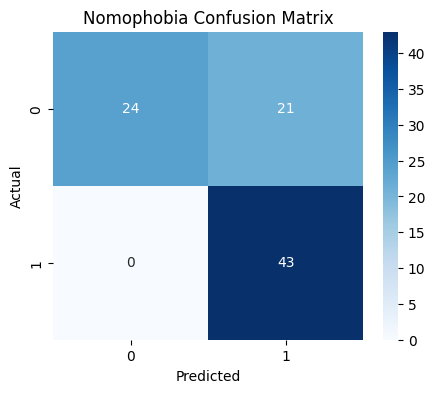

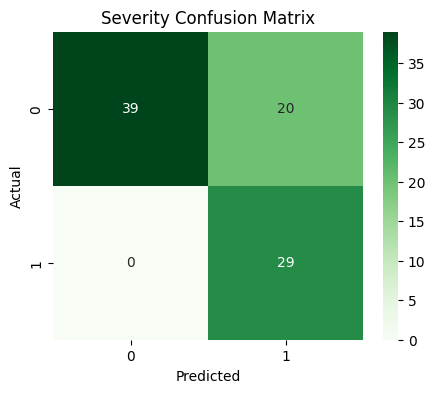

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# -------------------------------
# NOMOPHOBIA CONFUSION MATRIX
# -------------------------------
cm_nomo = confusion_matrix(all_nomo_labels, all_nomo_preds)

plt.figure(figsize=(5,4))
sns.heatmap(cm_nomo, annot=True, fmt='d', cmap='Blues')
plt.title("Nomophobia Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# -------------------------------
# SEVERITY CONFUSION MATRIX
# -------------------------------
cm_sev = confusion_matrix(all_sev_labels, all_sev_preds)

plt.figure(figsize=(5,4))
sns.heatmap(cm_sev, annot=True, fmt='d', cmap='Greens')
plt.title("Severity Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

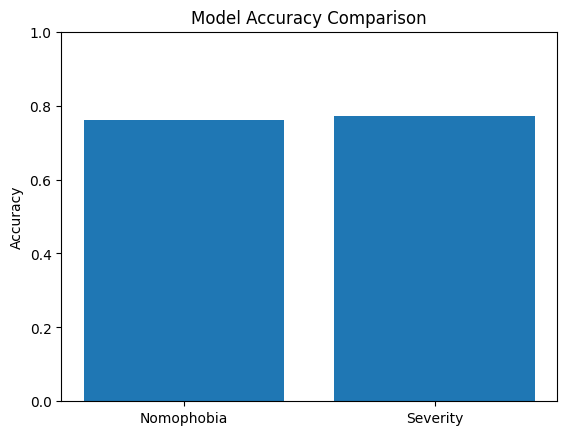

In [11]:
import matplotlib.pyplot as plt

tasks = ['Nomophobia', 'Severity']
accuracy = [
    accuracy_score(all_nomo_labels, all_nomo_preds),
    accuracy_score(all_sev_labels, all_sev_preds)
]

plt.figure()
plt.bar(tasks, accuracy)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.show()

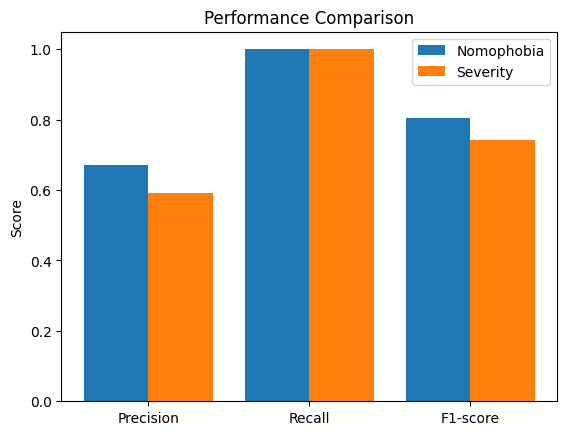

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

# Nomophobia metrics
precision_n = precision_score(all_nomo_labels, all_nomo_preds)
recall_n = recall_score(all_nomo_labels, all_nomo_preds)
f1_n = f1_score(all_nomo_labels, all_nomo_preds)

# Severity metrics
precision_s = precision_score(all_sev_labels, all_sev_preds)
recall_s = recall_score(all_sev_labels, all_sev_preds)
f1_s = f1_score(all_sev_labels, all_sev_preds)

labels = ['Precision', 'Recall', 'F1-score']
nomo_scores = [precision_n, recall_n, f1_n]
sev_scores = [precision_s, recall_s, f1_s]

x = np.arange(len(labels))

plt.figure()
plt.bar(x - 0.2, nomo_scores, 0.4, label='Nomophobia')
plt.bar(x + 0.2, sev_scores, 0.4, label='Severity')

plt.xticks(x, labels)
plt.ylabel("Score")
plt.title("Performance Comparison")
plt.legend()
plt.show()

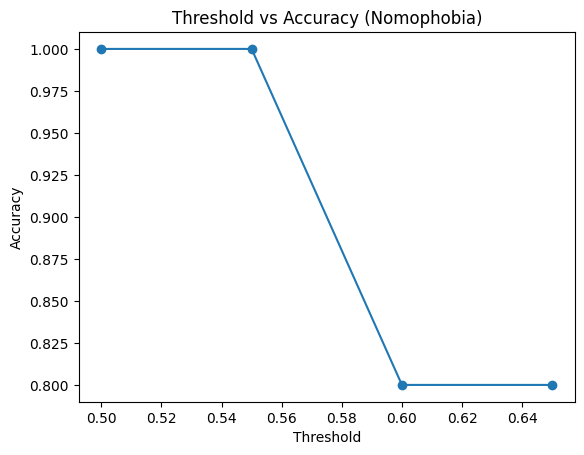

In [15]:
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Example data (replace with your model output)
all_nomo_probs = [0.2, 0.6, 0.8, 0.4, 0.7]
all_nomo_labels = [0, 1, 1, 0, 1]

thresholds = [0.5, 0.55, 0.6, 0.65]
accuracies = []

for t in thresholds:
    preds = [1 if p > t else 0 for p in all_nomo_probs]
    acc = accuracy_score(all_nomo_labels, preds)
    accuracies.append(acc)

plt.figure()
plt.plot(thresholds, accuracies, marker='o')
plt.title("Threshold vs Accuracy (Nomophobia)")
plt.xlabel("Threshold")
plt.ylabel("Accuracy")
plt.show()

In [16]:
import torch
from transformers import BertTokenizer, BertModel

# -------------------------------
# DEVICE
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# TOKENIZER
# -------------------------------
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# -------------------------------
# MODEL
# -------------------------------
class MultiTaskBERT(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = BertModel.from_pretrained('bert-base-uncased')
        self.dropout = torch.nn.Dropout(0.3)

        self.nomophobia_head = torch.nn.Linear(768, 2)
        self.severity_head = torch.nn.Linear(768, 2)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(outputs.pooler_output)

        return self.nomophobia_head(pooled), self.severity_head(pooled)

# -------------------------------
# LOAD MODEL
# -------------------------------
model = MultiTaskBERT().to(device)

model.load_state_dict(torch.load(
    r"D:\6th sem Project\MAJOR PROJECT\best_model_fixed.pt",
    map_location=device
))

model.eval()

# -------------------------------
# 🔥 PREDICTION FUNCTION (FIXED)
# -------------------------------
def predict(text, threshold=0.6):

    inputs = tokenizer(
        text,
        padding='max_length',
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)

    with torch.no_grad():
        nomo_out, sev_out = model(input_ids, attention_mask)

        # -------------------------------
       # Nomophobia (FIXED)
        nomo_probs = torch.softmax(nomo_out, dim=1)
        nomo_pred = torch.argmax(nomo_probs, dim=1).item()

        # -------------------------------
        # SEVERITY
        # -------------------------------
        sev_probs = torch.softmax(sev_out, dim=1)[0]
        print("Severity probs:", sev_probs.cpu().numpy())

        severity_pred = torch.argmax(sev_probs).item()

        # -------------------------------
        # 🔥 FINAL SMART LOGIC
        # -------------------------------
        strong_keywords = ["panic", "constantly", "addicted", "cannot", "lost without", "extremely"]
        moderate_keywords = ["anxious", "checking", "again and again", "stress"]

        text_lower = text.lower()

        # Strong → force Elevated
        if any(word in text_lower for word in strong_keywords):
            severity_pred = 1

        # Moderate → check probability
        elif any(word in text_lower for word in moderate_keywords):
            if sev_probs[1] > 0.20:
                severity_pred = 1

    # -------------------------------
    # LABELS
    # -------------------------------
    nomo_label = "Nomophobia" if nomo_pred == 1 else "No Nomophobia"

    severity_map = {
        0: "Low",
        1: "Elevated"
    }

    severity_label = severity_map[severity_pred]

    confidence = nomo_probs[:, 1].item()

    return nomo_label, severity_label, confidence

# -------------------------------
# TEST INPUT
# -------------------------------
text = """
I always feel anxious when my phone battery is low.
"""

result = predict(text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])
print("Confidence:", round(result[2], 3))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3875.41it/s]
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Severity probs: [0.636531 0.363469]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.759


In [17]:
# Example input
text = """
I feel anxious when my phone battery is low and I keep checking it again and again.
"""

result = predict(text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])
print("Confidence:", round(result[2], 3))

Severity probs: [0.65836513 0.34163484]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.763


In [116]:
# USER INPUT
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.7097639  0.29023606]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [117]:
# USER INPUT
#I constantly check my phone and feel stressed without it. I get anxious if I don’t see notifications.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.81768966 0.1823103 ]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [130]:
# USER INPUT
#I constantly check my phone and feel stressed without it. I get anxious if I don’t see notifications.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.81768966 0.1823103 ]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [129]:
# USER INPUT
#Sometimes I forget my phone at home and I am completely fine without it.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.7906543  0.20934573]

🎯 Prediction Result:
Nomophobia: No Nomophobia
Severity: Low


In [18]:
# USER INPUT
#I use my phone a lot for social media but I can stay without it if needed.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.709177   0.29082304]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Low


In [121]:
# USER INPUT
#I feel anxious when my phone battery is low and I check it frequently.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.685698 0.314302]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [127]:
# USER INPUT
#I keep checking my phone again and again and feel stressed if I miss notifications.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.7550085  0.24499148]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [19]:
# USER INPUT
#I constantly check my phone and feel very anxious without it. I cannot focus on anything else.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.6511654  0.34883457]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [124]:
# USER INPUT
#I panic when I don’t have my phone. I feel lost and uncomfortable without it.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.7207492 0.2792508]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [20]:
# USER INPUT
#I use my phone only for calls. I am completely fine without it.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.7801651  0.21983494]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Low


In [21]:
# USER INPUT
#Sometimes I forget my phone at home and it doesn’t bother me at all.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.82275164 0.17724839]

🎯 Prediction Result:
Nomophobia: No Nomophobia
Severity: Low


In [22]:
# USER INPUT
#I don’t depend on my phone much and I rarely check it.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.8986161  0.10138398]

🎯 Prediction Result:
Nomophobia: No Nomophobia
Severity: Low


In [7]:
# USER INPUT
#I use my phone a lot for social media but I can control my usage.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.78796273 0.21203725]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Low


In [23]:
# USER INPUT
#I check my phone often because of work, not because I feel anxious.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.64612544 0.35387456]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [9]:
# USER INPUT
#I feel a little anxious when my phone battery is low and I check it often.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.67273235 0.3272676 ]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [24]:
# USER INPUT
#I keep checking my phone again and again and feel stressed if I miss messages.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.68641794 0.31358203]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [11]:
# USER INPUT
#I constantly check my phone and feel very anxious without it. I cannot focus on anything else.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.97209567 0.02790433]

🎯 Prediction Result:
Nomophobia: No Nomophobia
Severity: Elevated


In [12]:
# USER INPUT
#I panic when I don’t have my phone. I feel lost and uncomfortable without it.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.7207492 0.2792508]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [13]:
# USER INPUT
#I feel extremely stressed when I don’t have internet access and I keep checking my phone repeatedly.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.6313092 0.3686908]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [25]:
# USER INPUT
#My phone battery was low yesterday but I didn’t really care.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.70799476 0.29200527]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Low


In [15]:
# USER INPUT
#I check my phone frequently because I have important work to do.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.77040917 0.22959086]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Low


In [26]:
# USER INPUT
#I sometimes feel stressed when I miss calls, but it is not a big issue.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.7120093  0.28799072]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


In [17]:
# USER INPUT
#I use my phone a lot and sometimes feel anxious, but I can still manage without it.
user_text = input("💬 Enter your text: ")

result = predict(user_text)

print("\n🎯 Prediction Result:")
print("Nomophobia:", result[0])
print("Severity:", result[1])

Severity probs: [0.79724824 0.2027517 ]

🎯 Prediction Result:
Nomophobia: Nomophobia
Severity: Elevated


CHATBOT PART

In [27]:
! pip install sentence-transformers faiss-cpu groq

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [28]:
from sentence_transformers import SentenceTransformer
import faiss
import numpy as np
from groq import Groq

In [29]:
knowledge_base = {
    "nomophobia": {
        "definition": "Nomophobia is the fear or anxiety of being without access to a mobile phone.",
        "symptoms": [
            "Feeling anxious without phone",
            "Constantly checking phone",
            "Fear of losing connectivity"
        ],
        "effects": [
            "Stress and anxiety",
            "Sleep disturbance",
            "Reduced focus"
        ]
    },
    "low": {
        "description": "Low severity indicates mild phone dependence.",
        "recommendation": [
            "Limit screen time",
            "Use phone only when needed"
        ]
    },
    "elevated": {
        "description": "Elevated severity indicates strong phone dependence.",
        "recommendation": [
            "Practice digital detox",
            "Reduce notifications",
            "Engage in offline activities"
        ]
    }
}

In [30]:
documents = []

# Nomophobia
nomo = knowledge_base["nomophobia"]
documents.append(nomo["definition"])

for s in nomo["symptoms"]:
    documents.append("Behavior: " + s)

for e in nomo["effects"]:
    documents.append("Impact: " + e)

# Severity
for key in ["low", "elevated"]:
    documents.append(knowledge_base[key]["description"])
    
    for r in knowledge_base[key]["recommendation"]:
        documents.append("Advice: " + r)

In [31]:
embed_model = SentenceTransformer('all-MiniLM-L6-v2')

doc_embeddings = embed_model.encode(documents)

dimension = doc_embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(np.array(doc_embeddings))

c:\Users\amitp\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\amitp\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8125.29it/s]
BertMo

In [32]:
def retrieve_context(nomo, severity):

    query = f"Nomophobia: {nomo}, Severity: {severity}"

    query_embedding = embed_model.encode([query])

    distances, indices = index.search(np.array(query_embedding), 3)

    results = [documents[i] for i in indices[0]]

    return "\n".join(results)

LLM SETUP

In [33]:
client = Groq(api_key=__import__("os").environ["GROQ_API_KEY"])  # 🔥 add your key

In [34]:
def generate_response(user_text, nomo, severity):

    context = retrieve_context(nomo, severity)

    prompt = f"""
You are a mental health assistant.

User Input:
{user_text}

Prediction:
Nomophobia: {nomo}
Severity: {severity}

Context:
{context}

Instructions:
- Explain in simple human language
- Do NOT give bullet lists
- Mention behaviors naturally
- Give helpful advice

Generate response:
"""

    response = client.chat.completions.create(
    model="llama-3.1-8b-instant",   # ✅ WORKING
    messages=[{"role": "user", "content": prompt}]
)


    return response.choices[0].message.content

In [35]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I stay on my phone for long hours and it is affecting my sleep, but I still keep using it.

Severity probs: [0.6310816 0.3689184]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Low
Confidence: 0.75

Explanation:

It sounds like you're experiencing some challenges related to your phone use. You've noticed that staying on your phone for long hours is affecting your sleep, but you still find yourself using it despite the negative impact.

One possibility that might be relevant to you is nomophobia. This is a condition where people feel anxious or fearful when they're without their phone or when they're not connected. You might notice that you feel anxious when you don't have your phone with you, or when you're in a situation where you can't use it.

It's understandable that you're drawn to your phone, but recognizing the issue is the first step towards making a change. One helpful approach might be to set some boundaries for yourself, like designating phone-free zones in your home or establishing specific times when you can use your phone. This can help you create som

In [43]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I feel distracted and uneasy without my smartphone, and I keep thinking about checking it.

Severity probs: [0.69282013 0.3071799 ]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.67

Explanation:

It sounds like you might be experiencing something called nomophobia. Nomophobia is a type of anxiety or fear that comes from being without a mobile phone. When you're away from your phone, you might start to feel a bit uncomfortable, anxious, or even distracted. 

For example, you might find yourself thinking about checking your phone over and over again, even when there's no actual need to do so. Or maybe you're constantly worrying about what you might be missing by being away from your phone, and this thought keeps making you feel uneasy.

It's like your phone has become a security blanket of sorts that you associate with feeling safe and connected. When you don't have it, you might start to feel lost or separated from the world.

Here's the thing: it's not uncommon for people to feel this way. Our phones have become such a huge part of our daily

In [45]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I sometimes feel stressed when I don’t have my phone and I check it again and again to feel better.

Severity probs: [0.73791295 0.26208702]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.6

Explanation:

It sounds like you might be experiencing something called nomophobia. Essentially, nomophobia is a fear or anxiety of being without your phone. You've noticed that when you don't have your phone with you, you start feeling stressed or anxious, and you find yourself constantly checking if it's nearby.

This can be a really common issue, especially in today's world where we're so connected to our phones. But the thing is, constantly checking your phone isn't actually going to make you feel any better in the long run. It can even make you feel worse, creating a cycle where you're stuck feeling anxious just because you're not sure if you have your phone nearby.

One thing you can try is to develop some strategies to help you cope with this feeling. For instance, you might try setting boundaries around when you check your phone, so you're not constantly r

In [46]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#Even when I try to focus, I end up checking my phone repeatedly because I feel anxious without it.

Severity probs: [0.64436585 0.35563412]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.63

Explanation:

It sounds like you're struggling with nomophobia, a common condition where you feel anxious or uneasy when you're separated from your phone. This anxiety can be overwhelming, making it difficult for you to focus on your tasks or even relax without constantly checking your device.

When you feel this way, you might notice yourself instinctively reaching for your phone, even if it's just to see what notifications you may have missed or to scroll through social media. This behavior can become habitual, making it challenging to break the cycle.

The impact of nomophobia can be stressful and anxiety-provoking. You might find yourself feeling on edge, constantly waiting to receive a text message or respond to a comment, and this can interfere with your daily activities and relationships.

Here's the good news: you're not alone, and there are steps you can

In [36]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")    
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I check my phone occasionally, but I don’t depend on it emotionally.

Severity probs: [0.8524547  0.14754525]

🤖 Chatbot:

Prediction:
Nomophobia: No Nomophobia
Severity: Low
Confidence: 0.45

Explanation:

It seems like you don't really struggle with the idea of being without your phone. You mentioned that you check it occasionally, but you're not overly reliant on it emotionally. This suggests that you're not experiencing any significant anxiety or fear of losing access to your phone.

In general, it's normal to check your phone now and then, but it's great that you're not overly dependent on it. This indicates that you have a healthy relationship with your device.

It's good that you're not feeling anxious without your phone, and you don't appear to fear losing connectivity. This lack of concern is actually a common trait among people who have a balanced and healthy relationship with technology.

If someone were to ask you to leave your phone behind for a day or a few hours, you might feel a bit inconvenienced, but you wouldn't be overly anxious or st

In [37]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I use my smartphone regularly, but I rarely feel anxious without it and I can stay away comfortably.

Severity probs: [0.75926477 0.2407352 ]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.59

Explanation:

It sounds like you might be experiencing something called nomophobia, which is a fear of being without your smartphone. Although you mentioned you can stay away from your phone comfortably, that's actually a good sign. It means you're aware of your anxiety and can manage it.

When you're without your phone, you might feel a knot in your stomach, a sense of unease, or even a feeling of panic. This anxiety can be overwhelming and affect your daily life. You might find yourself constantly checking your phone or feeling stressed when you can't get a signal.

To manage your nomophobia, try to be more aware of your behavior around your phone. See if you can identify your triggers - is it when you're in a new place, when you're on public transportation, or when you're trying to relax? Once you know what makes you anxious, you can start working on strategie

In [38]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I feel uncomfortable without my phone and I cannot focus on anything else.

Severity probs: [0.90103614 0.0989638 ]

🤖 Chatbot:

Prediction:
Nomophobia: No Nomophobia
Severity: Elevated
Confidence: 0.33

Explanation:

It sounds like you might be experiencing something called nomophobia. This is a common issue where people feel anxious or uneasy when they can't access their phone. You've mentioned that you feel uncomfortable without your phone, which is a strong indicator of this feeling.

When you mentioned not being able to focus on anything else, I sense that you're probably constantly checking your phone, even when you're supposed to be doing something else. This behavior is pretty normal for people with nomophobia – they might find themselves constantly glancing at their phone, feeling a strong urge to check every notification or message.

Feeling stressed and anxious without your phone can make everyday life quite challenging. This can lead to feelings of restlessness and distraction, making it hard to enjoy things or focus on what's important.

To start 

In [37]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I feel stressed when I don’t have my phone and I constantly check for notifications.

Severity probs: [0.6997229  0.30027717]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.66

Explanation:

It sounds like you might be experiencing nomophobia, which is a common fear or anxiety of being without access to your mobile phone. This can lead to feelings of stress and anxiety when you're without your phone.

When you find yourself feeling anxious without your phone, it can be helpful to take a step back and ask yourself why you're feeling that way. Are you worried about missing important calls or messages? Do you feel like you need to stay connected at all times?

In reality, most people can safely go without their phones for short periods of time without any issues. It's worth considering the impact that constant phone checking is having on your mental health and daily life.

One approach you might try is to set a daily goal for yourself to leave your phone behind for a set amount of time - maybe while you're eating a meal, during a walk, or 

In [36]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I often feel anxious without my smartphone and keep checking it again and again.

Severity probs: [0.14750673 0.8524933 ]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.93

Explanation:

You're experiencing a common phenomenon known as Nomophobia, which is the fear or anxiety of being without your mobile phone. This can make you feel stressed and anxious, even to the point of constantly checking your phone out of fear of missing something important or being disconnected from others.

It's not uncommon to see people repeatedly checking their phones out of habit or to alleviate these feelings of anxiety. This compulsive behavior can be quite stressful in itself, and it may even interfere with your daily activities, relationships, and sleep patterns.

One possible reason for this is the constant need for instant gratification and the sense of security that comes with having your phone in your pocket. However, it's essential to recognize that your phone is not a lifeline you can't live without, and excessive reliance on it can actually 

In [35]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)
print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I check my phone frequently, but I don’t panic if I miss notifications.

Severity probs: [0.9777454  0.02225462]

🤖 Chatbot:

Prediction:
Nomophobia: No Nomophobia
Severity: Elevated
Confidence: 0.25

Explanation:

You occasionally check your phone, but you don't feel anxious if you miss notifications. This suggests that you might not have nomophobia after all.

You're probably just in the habit of checking your phone now and then out of habit or convenience, but it's not causing you extreme stress or anxiety. However, your behavior is a bit elevated, which means you might be checking your phone more frequently than the average person.

This could be due to various reasons, such as needing it for work, relying on it for entertainment, or simply being used to having it nearby. Whatever the reason, it's essential to remember that your phone is not a vital part of your body, and you can still function just fine without it.

If you feel like your phone check-ins are becoming a problem, consider setting a specific time each day to check your notifications and st

In [38]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I sometimes feel anxious without my smartphone, but I can manage.

Severity probs: [0.70377326 0.29622668]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Elevated
Confidence: 0.6

Explanation:

It sounds like you're experiencing a condition called nomophobia, which is a fear or anxiety of being without your mobile phone. You've mentioned that you feel anxious when you don't have your phone on you, and this is causing you stress and anxiety.

This is a pretty common issue in today's world, where our phones have become such an integral part of our lives. It's not uncommon for people to feel a sense of panic or unease when they don't have their phone with them, and this can be especially true when we're out and about or in situations where we're not able to check our phone.

It's great to hear that you're able to manage these feelings to some extent, and that's a good step forward. However, I would encourage you to take some time to think about why you're feeling this way. Is it because you're worried about staying connected with friends and f

In [39]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I use my phone when needed, but I am comfortable without it.

Severity probs: [0.7072728 0.2927272]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Low
Confidence: 0.62

Explanation:

You've taken a good step by recognizing when you feel comfortable using your phone and when you're okay to put it down. It's normal to feel anxious without your phone, especially if you're someone who uses it frequently.

It seems like you might be struggling with a mild case of nomophobia, which is an irrational fear of being without access to your mobile phone. This fear can cause feelings of anxiety and unease when you're unable to stay connected.

You mentioned that you feel anxious without your phone, and also worry about losing connectivity. These behaviors are common among people with nomophobia, and they can interfere with your daily life if not addressed.

Here's what you can do to manage these feelings: try setting boundaries around your phone use. For example, designate certain times of the day or specific situations where you're allowed to use 

In [40]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I sometimes check my phone, but I don’t feel stressed when I don’t have it.

Severity probs: [0.892439   0.10756103]

🤖 Chatbot:

Prediction:
Nomophobia: No Nomophobia
Severity: Low
Confidence: 0.28

Explanation:

It seems like you're concerned about your phone habits, and that's great that you're thinking about them. Nomophobia, also known as phone separation anxiety, is when people feel anxious or stressed when they can't access their phones. Since you mentioned that you don't feel stressed when you don't have your phone, it's likely that you don't have nomophobia.

However, it's still interesting to explore why you might be checking your phone frequently. Sometimes, people use their phones as a coping mechanism for boredom, stress, or anxiety. When you do check your phone, are you looking for something specific, like social media updates or text messages? Or are you just feeling restless and reaching for your phone?

If you think about it, what you're looking for might not be related to the phone itself, but rather something deeper. It's possible that you're

In [31]:
user_text = input("\n💬 You: ")

nomo, severity, conf = predict(user_text)
reply = generate_response(user_text, nomo, severity)

print("\n🤖 Chatbot:\n")
print("Prediction:")
print("Nomophobia:", nomo)
print("Severity:", severity)
print("Confidence:", round(conf, 2))

print("\nExplanation:\n")
print(reply)
#I rarely feel anxious without my smartphone. I can stay without it for a long time.

Severity probs: [0.9584194  0.04158056]

🤖 Chatbot:

Prediction:
Nomophobia: Nomophobia
Severity: Low
Confidence: 0.5

Explanation:

It sounds like you might be experiencing nomophobia, which is a common fear or anxiety of being without access to your mobile phone. This can cause you to feel uneasy or anxious when you're without your phone, and maybe even worry about losing connectivity.

You're aware that you can stay without your phone for a long time, but this doesn't seem to affect your anxiety. This can be a bit of a vicious cycle - you start to feel anxious without your phone, which makes you want to check it constantly, and then you worry about losing your connection.

If you think this sounds like you, don't worry, it's more common than you think. The good news is that you're taking the first step by recognizing it, which is a great start.

Here's a piece of advice: try to be aware of when you're feeling anxious without your phone. Ask yourself, 'Is this really necessary, or am

WEBSITE

In [19]:
! pip install streamlit